Version B — BERT variant `sweep_b_lr3e-5`: learning rate raised from 2e-5 (baseline) to 3e-5, all other hyperparameters unchanged (`bert-base-uncased, batch_size=16, epochs=3`). Part of the LR/batch-size sweep.

In [1]:
%pip install transformers datasets torch accelerate scikit-learn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import pickle
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)

TAG = "sweep_b_lr3e-5"
CHECKPOINT = "bert-base-uncased"
LEARNING_RATE = 3e-05
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 3

print("CUDA available:", torch.cuda.is_available())
print(f"Variant {TAG}: checkpoint={CHECKPOINT}, lr={LEARNING_RATE}, train_batch={TRAIN_BATCH_SIZE}, eval_batch={EVAL_BATCH_SIZE}")

C:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
Variant sweep_b_lr3e-5: checkpoint=bert-base-uncased, lr=3e-05, train_batch=16, eval_batch=32


In [3]:
SPLITS_DIR = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
RESULTS_DIR = Path("../../../results/bert")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = Path("../../weights/bert_variants") / TAG
MODELS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)

LABEL_ORDER = list(label_encoder.classes_)
NUM_CLASSES = len(LABEL_ORDER)
id2label = {i: c for i, c in enumerate(LABEL_ORDER)}
label2id = {c: i for i, c in enumerate(LABEL_ORDER)}

for df in (train_df, val_df, test_df):
    df["label"] = label_encoder.transform(df["category"])

print("Train/val/test sizes:", len(train_df), len(val_df), len(test_df))
print("Classes:", LABEL_ORDER)

Train/val/test sizes: 224828 48178 48178
Classes: ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']


In [4]:
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

SAMPLE_N = 20000
sample_lengths = (
    train_df["text"]
    .sample(n=min(SAMPLE_N, len(train_df)), random_state=SEED)
    .apply(lambda t: len(tokenizer.encode(t, add_special_tokens=True)))
)
p95_len = int(np.percentile(sample_lengths, 95))
MAX_LENGTH = int(np.clip(p95_len, 1, 512))
MAX_LENGTH = min(((MAX_LENGTH + 7) // 8) * 8, 512)  # round up to a multiple of 8, still capped at 512
print(f"95th percentile subword length: {p95_len}, MAX_LENGTH: {MAX_LENGTH}")

def tokenize_fn(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)

train_ds = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True)).map(
    tokenize_fn, batched=True, remove_columns=["text"]
)
val_ds = Dataset.from_pandas(val_df[["text", "label"]].reset_index(drop=True)).map(
    tokenize_fn, batched=True, remove_columns=["text"]
)
test_ds = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True)).map(
    tokenize_fn, batched=True, remove_columns=["text"]
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (857 > 512). Running this sequence through the model will result in indexing errors


95th percentile subword length: 727, MAX_LENGTH: 512


Map:   0%|          | 0/224828 [00:00<?, ? examples/s]

Map:   0%|          | 1000/224828 [00:00<00:23, 9663.65 examples/s]

Map:   1%|▏         | 3000/224828 [00:00<00:18, 11881.05 examples/s]

Map:   2%|▏         | 5000/224828 [00:00<00:16, 13140.51 examples/s]

... (159 outputs left out)

Map:  89%|████████▉ | 43000/48178 [00:03<00:00, 10295.80 examples/s]

Map:  93%|█████████▎| 45000/48178 [00:03<00:00, 11202.67 examples/s]

Map:  98%|█████████▊| 47000/48178 [00:03<00:00, 11731.82 examples/s]

Map: 100%|██████████| 48178/48178 [00:03<00:00, 12996.87 examples/s]

In [5]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
model = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    report = classification_report(labels, preds, target_names=LABEL_ORDER, output_dict=True, zero_division=0)
    return {
        "accuracy": report["accuracy"],
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
    }

training_args = TrainingArguments(
    output_dir=str(MODELS_DIR),
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    data_seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4229.03it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [6]:
start_time = time.time()
trainer.train()
train_time_sec = time.time() - start_time
print(f"[{TAG}] training took {train_time_sec:.1f}s")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.352838,0.326334,0.892399,0.877407,0.892299
2,0.245956,0.329504,0.899892,0.884853,0.899813
3,0.127104,0.410651,0.904126,0.889735,0.904050


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.72it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.70it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.88it/s]

... (3 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.33it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

[transformers] There were unexpected keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.beta', 'bert.embeddings.LayerNorm.gamma', 'bert.encoder.layer.0.attention.output.LayerNorm.beta', 'bert.encoder.layer.0.attention.output.LayerNorm.gamma', 'bert.encoder.layer.0.output.LayerNorm.beta', 'bert.encoder.layer.0.output.LayerNorm.gamma', 'bert.encoder.layer.1.attention.output.LayerNorm.beta', 'bert.encoder.layer.1.attention.output.LayerNorm.gamma', 'bert.encoder.layer.1.output.LayerNorm.beta', 'bert.encoder.layer.1.output.LayerNorm.gamma', 'bert.encoder.layer.2.attention.output.LayerNorm.beta', 'bert.encoder.layer.2.attention.output.LayerNorm.gamma', 'bert.encoder.layer.2.output.LayerNorm.beta', 'bert.encoder.layer.2.output.LayerNorm.gamma', 'bert.encoder.layer.3.attention.output.LayerNorm.beta', 'bert.encoder.layer.3.attention.output.LayerNorm.gamma', 'bert.encoder.layer.3.output.LayerNorm.beta', 'bert.encoder.layer.3.output.LayerNorm.gamma', 'bert.encoder.layer.4.attention.

[sweep_b_lr3e-5] training took 16132.5s


               precision    recall  f1-score   support

     Business       0.88      0.86      0.87      6323
Entertainment       0.92      0.92      0.92     12064
       Health       0.84      0.84      0.84      4197
     Politics       0.88      0.89      0.88      6238
      Science       0.79      0.79      0.79      1609
       Sports       0.97      0.96      0.96      5854
   Technology       0.89      0.92      0.91      5827
        World       0.92      0.91      0.92      6066

     accuracy                           0.90     48178
    macro avg       0.89      0.89      0.89     48178
 weighted avg       0.90      0.90      0.90     48178

[sweep_b_lr3e-5] test accuracy: 0.9016, macro_f1: 0.8866
Inference time: 249.49s total, 5.179 ms/sample


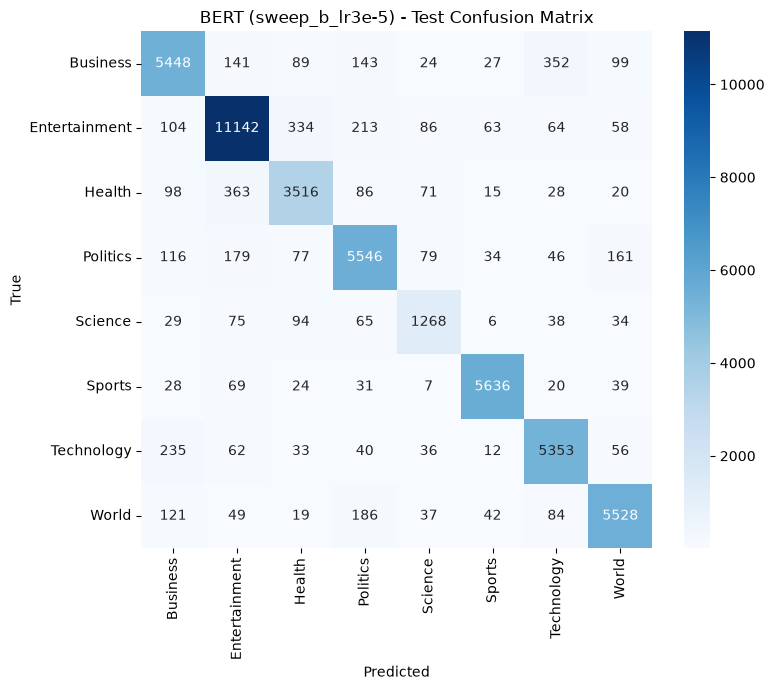

In [7]:
inf_start = time.time()
test_output = trainer.predict(test_ds)
inf_time_sec = time.time() - inf_start

y_pred = np.argmax(test_output.predictions, axis=-1)
y_test = np.array(test_ds["label"])

report_dict = classification_report(y_test, y_pred, target_names=LABEL_ORDER, output_dict=True, zero_division=0)
print(classification_report(y_test, y_pred, target_names=LABEL_ORDER, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
test_accuracy = report_dict["accuracy"]
test_macro_f1 = report_dict["macro avg"]["f1-score"]
print(f"[{TAG}] test accuracy: {test_accuracy:.4f}, macro_f1: {test_macro_f1:.4f}")
print(f"Inference time: {inf_time_sec:.2f}s total, {inf_time_sec / len(test_df) * 1000:.3f} ms/sample")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"BERT ({TAG}) - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "BERT_b_confusion_matrix.png", dpi=150)
plt.show()

In [8]:
trainer.save_model(str(MODELS_DIR))
tokenizer.save_pretrained(str(MODELS_DIR))

metrics = {
    "model_family": "bert",
    "model_name": CHECKPOINT,
    "variant": TAG,
    "run_timestamp": pd.Timestamp.now("UTC").isoformat(),
    "label_order": LABEL_ORDER,
    "config": {
        "max_length": MAX_LENGTH,
        "batch_size": TRAIN_BATCH_SIZE,
        "eval_batch_size": EVAL_BATCH_SIZE,
        "epochs_planned": EPOCHS,
        "epochs_trained": trainer.state.epoch,
        "learning_rate": LEARNING_RATE,
        "use_class_weights": False,
    },
    "train": {
        "n_train": len(train_df),
        "n_val": len(val_df),
        "train_time_sec": train_time_sec,
        "epochs_trained": trainer.state.epoch,
        "history": {"log_history": trainer.state.log_history},
    },
    "test": {
        "n_test": len(test_df),
        "accuracy": float(test_accuracy),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class": {
            cls: {
                "precision": float(report_dict[cls]["precision"]),
                "recall": float(report_dict[cls]["recall"]),
                "f1": float(report_dict[cls]["f1-score"]),
                "support": int(report_dict[cls]["support"]),
            }
            for cls in LABEL_ORDER
        },
        "confusion_matrix": cm.tolist(),
        "inference_time_sec_total": inf_time_sec,
        "inference_time_ms_per_sample": inf_time_sec / len(test_df) * 1000,
    },
    "environment": {
        "framework": "pytorch+transformers",
        "framework_version": torch.__version__,
        "device": "GPU" if torch.cuda.is_available() else "CPU",
        "seed": SEED,
    },
}

with open(RESULTS_DIR / "BERT_b_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

for sub in MODELS_DIR.glob("checkpoint-*"):
    if sub.is_dir():
        shutil.rmtree(sub)

print("Saved:")
print(" ", MODELS_DIR)
print(" ", RESULTS_DIR / "BERT_b_metrics.json")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.29it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.28it/s]

Saved:
  ..\..\weights\bert_variants\sweep_b_lr3e-5
  ..\..\..\results\bert\BERT_b_metrics.json
